In [341]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import matplotlib.pyplot as plt

# Problem 1

## 1.1
Report the five following “95%” confidence intervals (CI) for $\tau^*(\mathbb{P})$:

In [342]:
np.random.seed(42) # Seed for reproducibility

In [343]:
n: int = 100

samples = []
for _ in range(n):
    w_i = np.random.uniform(-2, 2)
    x_i = np.random.normal(w_i**4, 1)
    y_i = np.random.normal(x_i + w_i**2, w_i**2)

    samples.append((w_i, x_i, y_i))

samples = np.array(samples)

samples[0]

array([-0.50183952, -1.04845527, -0.71629911])

In [344]:
X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
y = samples[:, 2]

In [345]:
coefs, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

tau_hat = coefs[-1]
f"tau (hat): {tau_hat:.4f}"

'tau (hat): 1.2364'

### 1.1 (a)

In [346]:
alpha: float = 0.05

In [347]:
residual_var = y - X @ coefs
sigma2_hat = residual_var @ residual_var / (n - 3)
Gamma_hat = sigma2_hat * np.linalg.inv(X.T @ X)

Gamma_hat

array([[ 0.07977946, -0.00243349, -0.0083576 ],
       [-0.00243349,  0.03483993,  0.00123023],
       [-0.0083576 ,  0.00123023,  0.00239366]])

In [348]:
t_stat = stats.t.ppf(1 - alpha / 2, df = n - 3)

In [349]:
se_hat_tau_hat = np.sqrt(Gamma_hat[2, 2])

print(f"CI computed assuming homoscedasticity and linearity: [{tau_hat - t_stat * se_hat_tau_hat:.4f}, {tau_hat + t_stat * se_hat_tau_hat:.4f}]")

CI computed assuming homoscedasticity and linearity: [1.1393, 1.3335]


### 1.1 (b)

In [350]:
resid_b = y - X @ coefs
M = (X * resid_b[:, None]**2).T @ X
Inv = np.linalg.inv(X.T @ X)

Gamma_hat = Inv @ M @ Inv

In [351]:
se_hat_tau_hat = np.sqrt(Gamma_hat[2, 2])

print(f"CI using Eicker-Huber-White robust standard error: [{tau_hat - t_stat * se_hat_tau_hat:.4f}, {tau_hat + t_stat * se_hat_tau_hat:.4f}]")

CI using Eicker-Huber-White robust standard error: [1.0862, 1.3866]


### 1.1 (c)

In [352]:
tau_boostrap_replicates_multi = []

for b in range(0, 1000):
    # Randomly sample 100 indices; sampling with replacement using uniform weighting scheme
    indices = np.random.randint(low = 0, high = n, size=n)
    X_b = X[indices, :]
    y_b = y[indices]

    coefs_b, _, _, _ = np.linalg.lstsq(X_b, y_b, rcond = None)

    tau_boostrap_replicates_multi.append(coefs_b[-1])

In [353]:
lower_percentile_tau = np.quantile(tau_boostrap_replicates_multi, q = alpha / 2)
upper_percentile_tau = np.quantile(tau_boostrap_replicates_multi, q = 1 - alpha / 2)

print(f"CI using the percentile bootstrap with multinomial resampling: [{lower_percentile_tau:.4f}, {upper_percentile_tau:.4f}]")

CI using the percentile bootstrap with multinomial resampling: [1.1004, 1.3956]


### 1.1 (d)

In [354]:
tau_boostrap_replicates_expo = []

for b in range(0, 1000):
    # Exponential weighting
    expo_weights_b = np.random.exponential(scale = 1, size = n)
    sqrt_w = np.sqrt(expo_weights_b)

    coefs_b, _, _, _ = np.linalg.lstsq(X * sqrt_w[:, None], y * sqrt_w, rcond = None)

    tau_boostrap_replicates_expo.append(coefs_b[-1])

In [355]:
lower_percentile_tau = np.quantile(tau_boostrap_replicates_expo, q = alpha / 2)
upper_percentile_tau = np.quantile(tau_boostrap_replicates_expo, q = 1 - alpha / 2)

print(f"CI using the percentile bootstrap based on exponential weights: [{lower_percentile_tau:.4f}, {upper_percentile_tau:.4f}]")

CI using the percentile bootstrap based on exponential weights: [1.1015, 1.3775]


### 1.1 (e)

In [356]:
t_bootstrap_replicates_multi = []

for b in range(0, 1000):
    # Randomly sample 100 indices; sampling with replacement using uniform weighting
    indices = np.random.randint(low = 0, high = n, size=n)
    X_b = X[indices, :]
    y_b = y[indices]

    coefs_b, _, _, _ = np.linalg.lstsq(X_b, y_b, rcond = None)

    resid = (y - X @ coefs)
    M_b = (X_b * resid_b[:, None]**2).T @ X_b

    Inv_b = np.linalg.inv(X_b.T @ X_b)
    se_b = np.sqrt((Inv_b @ M_b @ Inv_b)[2, 2])

    t_b = (coefs_b[-1] - tau_hat) / se_b

    t_bootstrap_replicates_multi.append(t_b)

In [357]:
lower_percentile_t = np.quantile(t_bootstrap_replicates_multi, q = alpha / 2)
upper_percentile_t = np.quantile(t_bootstrap_replicates_multi, q = 1 - alpha / 2)

print(f"CI using the bootstrap t: [{tau_hat - se_hat_tau_hat * upper_percentile_t:.4f}, {tau_hat - se_hat_tau_hat * lower_percentile_t:.4f}]")

CI using the bootstrap t: [0.9920, 1.4840]


## 1.2

Show two histograms of the 1000 bootstrap estimates of $\hat{\tau}$ (for both the multinomial bootstrap and exponentially-weighted bootstrap). Compare to the histogram of Part 4 of Problem 2 from HW1.

In [358]:
tau_estimates_homework1 = []

for _ in range(1000):

    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)

    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]

    b, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

    tau_estimates_homework1.append(b[-1])

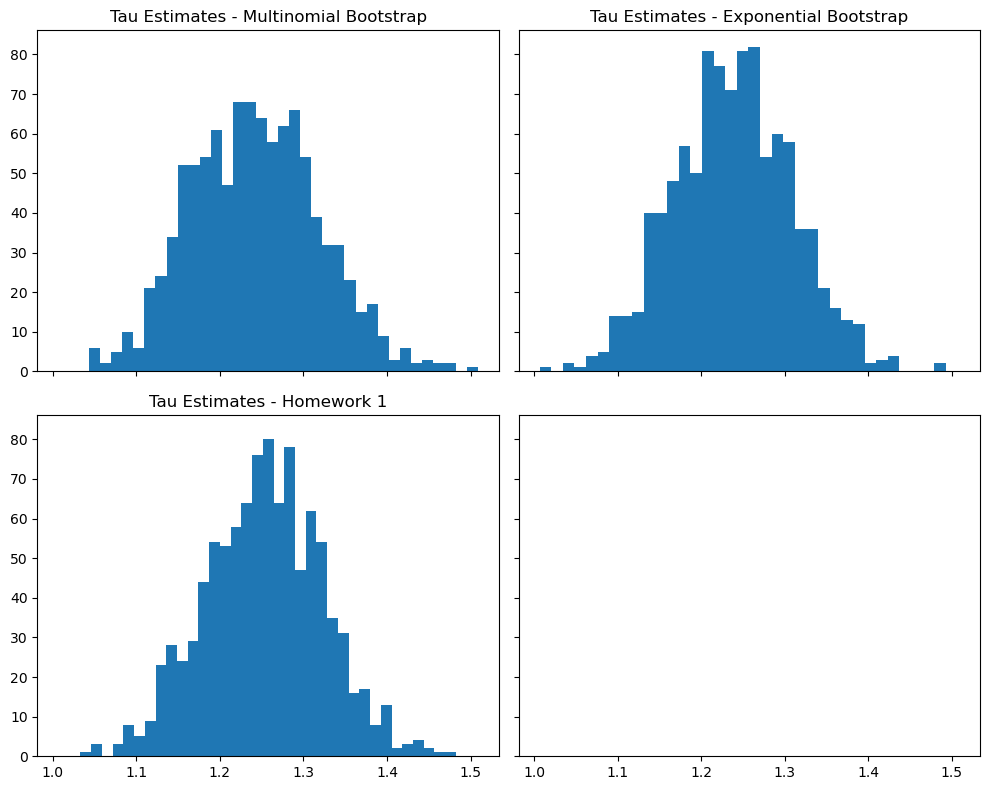

In [359]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

axs[0, 0].hist(x = tau_boostrap_replicates_multi, bins = 35)
axs[0, 0].set_title("Tau Estimates - Multinomial Bootstrap")

axs[0, 1].hist(x = tau_boostrap_replicates_expo, bins = 35)
axs[0, 1].set_title("Tau Estimates - Exponential Bootstrap")

axs[1, 0].hist(x = tau_estimates_homework1, bins = 35)
axs[1, 0].set_title("Tau Estimates - Homework 1")

plt.tight_layout()
plt.show()

### Comparison:

- All look roughly normal.

- The multinomial is slightly wider and shorter than the exponential distribution and homework 1 distribution.

## 1.3 & 1.4

Now repeat the above simulation 1000 times (as in Part 4 of Problem 2 from HW1). Report the coverage of the first two CIs (A and B): what proportion of the 1000 CIs contain $\tau^*(\mathbb{P})$ (computed separately for the CIs in A and B). Which CI has better coverage?

Extra credit (1 point): Do the task from Part 3 for the Bootstrap CIs as well. This may take a while to run since you need to fit the linear regression 1000 × 1000 times.

In [360]:
tau_star = 1 + 7680 / 30247     # Computed analytically in homework 1

In [361]:
a_res = []

for _ in range(0, 1000):
    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)
    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]

    coefs, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    tau_hat = coefs[-1]

    rss = 0
    for i in range(0, n):
        rss += (y[i] - X[i] @ coefs)**2
    sigma2_hat = rss / (n - 3)

    Gamma_hat = sigma2_hat * np.linalg.inv(X.T @ X)
    se_hat_tau_hat = np.sqrt(Gamma_hat[2, 2])
    
    a_res.append((tau_hat - t_stat * se_hat_tau_hat, tau_hat + t_stat * se_hat_tau_hat))

In [362]:
b_res = []

for _ in range(0, 1000):
    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)
    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]

    coefs, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    tau_hat = coefs[-1]

    resid = (y - X @ coefs)
    M = (X * resid[:, None]**2).T @ X

    Inv = np.linalg.inv(X.T @ X)
    Gamma_hat = Inv @ M @ Inv
    se_hat_tau_hat = np.sqrt(Gamma_hat[2, 2])

    b_res.append((tau_hat - t_stat * se_hat_tau_hat, tau_hat + t_stat * se_hat_tau_hat))

In [363]:
# For C

c_res = []
for _ in range(0, 1000):
    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)
    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]

    tau_boostrap_replicates_multi = []
    for b in range(0, 1000):
        # Randomly sample 100 indices; sampling with replacement using uniform weighting scheme
        indices = np.random.randint(low = 0, high = n, size=n)
        X_b = X[indices, :]
        y_b = y[indices]

        coefs_b, _, _, _ = np.linalg.lstsq(X_b, y_b, rcond = None)

        tau_boostrap_replicates_multi.append(coefs_b[-1])

    c_res.append((np.quantile(tau_boostrap_replicates_multi, q = alpha / 2), np.quantile(tau_boostrap_replicates_multi, q = 1 - alpha / 2)))

In [364]:
# For D

d_res = []
for _ in range(0, 1000):
    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)
    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]
    
    tau_boostrap_replicates_expo = []
    for b in range(0, 1000):
        # Exponential weighting
        expo_weights_b = np.random.exponential(scale = 1, size = n)
        sqrt_w = np.sqrt(expo_weights_b)

        coefs_b, _, _, _ = np.linalg.lstsq(X * sqrt_w[:, None], y * sqrt_w, rcond = None)

        tau_boostrap_replicates_expo.append(coefs_b[-1])

    d_res.append((np.quantile(tau_boostrap_replicates_expo, q = alpha / 2), np.quantile(tau_boostrap_replicates_expo, q = 1 - alpha / 2)))

In [365]:
# For E

e_res = []
for _ in range(0, 1000):
    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)
    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]

    coefs, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    tau_hat = coefs[-1]

    resid = y - X @ coefs
    Inv = np.linalg.inv(X.T @ X)
    M = (X * resid[:, None]**2).T @ X
    se_hat_tau_hat = np.sqrt((Inv @ M @ Inv)[2, 2])

    t_bootstrap_replicates_multi = []
    for b in range(0, 1000):
        # Randomly sample 100 indices; sampling with replacement using uniform weighting
        indices = np.random.randint(low = 0, high = n, size=n)
        X_b = X[indices, :]
        y_b = y[indices]

        coefs_b, _, _, _ = np.linalg.lstsq(X_b, y_b, rcond = None)

        resid_b = y_b - X_b @ coefs_b
        Inv_b = np.linalg.inv(X_b.T @ X_b)
        M_b = (X_b * resid_b[:, None]**2).T @ X_b
        se_b = np.sqrt((Inv_b @ M_b @ Inv_b)[2, 2])

        t_b = (coefs_b[-1] - tau_hat) / se_b

        t_bootstrap_replicates_multi.append(t_b)

    lower_percentile_t = np.quantile(t_bootstrap_replicates_multi, q = alpha / 2)
    upper_percentile_t = np.quantile(t_bootstrap_replicates_multi, q = 1 - alpha / 2)
    e_res.append((tau_hat - se_hat_tau_hat * upper_percentile_t, tau_hat - se_hat_tau_hat * lower_percentile_t))

In [366]:
def coverage(res: list) -> float:
    res = np.array(res)
    return np.mean((tau_star >= res[:, 0]) & (tau_star <= res[:, 1]))

In [367]:
coverage_df = pd.DataFrame(
    data = {
        "A" : coverage(a_res),
        "B" : coverage(b_res),
        "C" : coverage(c_res),
        "D" : coverage(d_res),
        "E" : coverage(e_res),
    },
    index = [f'% coverage']
)

coverage_df

,A,B,C,D,E
% coverage,0.764,0.913,0.907,0.909,0.943


### Comments
-

-